# Pemeriksaan awal bundel (M0, bagian 7)
IF25-40304 · Peran 1 (Data dan Etika Data)

Taruh notebook ini sejajar dengan `train.csv`, `val.csv`, dan `images/` (atau ubah `DIR`), lalu **Run All**.
Sel terakhir menghasilkan ringkasan untuk ditempel ke proposal. Semua angka berasal dari eksekusi nyata.

Atribusi data: SEA-VL Indonesian subset (KORIKA-AI/sea-vl_crowdsourcing_id), CC BY-SA 4.0. Cahyawijaya et al. (2025), ACL.

In [ ]:
import hashlib, re, os
import numpy as np, pandas as pd
from PIL import Image
from IPython.display import display

DIR = "../bundle-mahasiswa"
os.chdir(DIR)

tr = pd.read_csv("train.csv"); va = pd.read_csv("val.csv")
tr["split"] = "train"; va["split"] = "val"
df = pd.concat([tr, va], ignore_index=True)
print("baris train / val:", len(tr), len(va))
print("kolom:", list(df.columns))
df.head()

baris train / val: 2072 275
kolom: ['image_id', 'file', 'caption_en', 'caption_id', 'native_lang', 'loc', 'category', 'relevance', 'caption_fit', 'img_quality', 'n_annotator', 'width', 'height', 'split']


,image_id,file,caption_en,caption_id,native_lang,loc,category,relevance,caption_fit,img_quality,n_annotator,width,height,split
0,svl_140083991,images/svl_140083991.jpg,Nasi padang with roasted chicken,Nasi padang pakai ayam panggang,Indonesian (ind),Indonesia,kuliner,5.0,1.0,1.0,2,1008,1024,train
1,svl_140083992,images/svl_140083992.jpg,Nasi goreng with sunny side egg,Nasi goreng dengan telur ceplok,Indonesian (ind),Indonesia,kuliner,5.0,1.0,1.0,2,1024,1016,train
2,svl_140083994,images/svl_140083994.jpg,"Two portions of Mie Bangka, each with a clear ...","Dua porsi Mie Bangka, masing-masing dengan sup...",Indonesian (ind),Indonesia,lain-lain,5.0,1.0,1.0,3,1024,768,train
3,svl_140083997,images/svl_140083997.jpg,a photo of indonesian nasi goreng with fried e...,nasi goreng dengan telur dan sate,Indonesian (ind),"Indonesia, Malaysia",kuliner,5.0,1.0,1.0,2,1024,576,train
4,svl_140084000,images/svl_140084000.jpg,a photo of candi borobudur in indonesia,foto candi borobudur di indonesia,Indonesian (ind),Indonesia,arsitektur/bangunan,5.0,1.0,1.0,2,768,1024,train


## 1. Kelengkapan data

In [2]:
R = {}  # kumpulan hasil untuk ringkasan akhir
R["n_tr"], R["n_va"] = len(tr), len(va)

miss = [f for f in df["file"] if not os.path.exists(f)]
R["file_hilang"] = len(miss)
print("file gambar tidak ditemukan:", len(miss), miss[:5])

for c in ["caption_id", "caption_en", "category"]:
    kosong = int(df[c].isna().sum() + (df[c].astype(str).str.strip() == "").sum())
    R[f"kosong_{c}"] = kosong
    print(f"{c} kosong:", kosong)

file gambar tidak ditemukan: 0 []
caption_id kosong: 0
caption_en kosong: 0
category kosong: 0


## 2. File berulang dalam satu split
Penting: `recall()` di ToR memakai `truth = arange(N)`, artinya 1 gambar = 1 baris.
Kalau satu gambar punya banyak baris caption, Recall@K jadi bias.

In [3]:
for s, d in [("train", tr), ("val", va)]:
    n = int(d["file"].duplicated(keep=False).sum())
    R[f"file_berulang_{s}"] = n
    print(f"{s}: baris dengan file berulang:", n)
    if n:
        display(d[d["file"].duplicated(keep=False)].sort_values("file").head(10))

train: baris dengan file berulang: 0
val: baris dengan file berulang: 0


## 3. Hash gambar (md5 + dHash)

In [4]:
def md5(p):
    with open(p, "rb") as f: return hashlib.md5(f.read()).hexdigest()

def dhash(p):
    im = Image.open(p).convert("L").resize((9, 8), Image.LANCZOS)
    a = np.asarray(im, dtype=np.int16)
    return (a[:, 1:] > a[:, :-1]).flatten()

ok = df[df["file"].apply(os.path.exists)].reset_index(drop=True).copy()
ok["md5"] = ok["file"].apply(md5)
H = np.stack(ok["file"].apply(dhash).values)
print("gambar di-hash:", len(ok))

gambar di-hash: 2347


## 4. Duplikat identik (isi sama)

In [5]:
grp = ok.groupby("md5").agg(n_path=("file", "nunique"), n_split=("split", "nunique"), n_baris=("file", "size"))
dup_isi = grp[grp["n_path"] > 1]                 # beda path, isi sama
lintas = grp[(grp["n_split"] > 1)]               # muncul di train DAN val
R["exact_grup"], R["exact_lintas"] = len(dup_isi), len(lintas)
print("grup gambar identik (path beda):", len(dup_isi))
print("grup identik lintas train/val (LEAKAGE):", len(lintas))
display(ok[ok["md5"].isin(lintas.index)].sort_values("md5")[["file", "split", "category", "md5"]].head(20))

grup gambar identik (path beda): 0
grup identik lintas train/val (LEAKAGE): 0


,file,split,category,md5


## 5. Near-duplicate (dHash, Hamming ≤ THR)

In [6]:
THR = 5
m = ok["md5"].values
sp = ok["split"].values
near = []
for i in range(len(ok)):
    d = (H[i] != H[i + 1:]).sum(1)
    for j in np.where(d <= THR)[0]:
        k = i + 1 + j
        if m[i] != m[k]:
            near.append((i, k, int(d[j])))
R["near"] = len(near)
R["near_lintas"] = sum(sp[a] != sp[b] for a, b, _ in near)
print(f"pasangan near-duplicate (Hamming<={THR}):", R["near"], "| lintas split:", R["near_lintas"])

pasangan near-duplicate (Hamming<=5): 3 | lintas split: 1


hamming=0 | train:images/svl_141004060.jpg  vs  val:images/svl_143496781.jpg


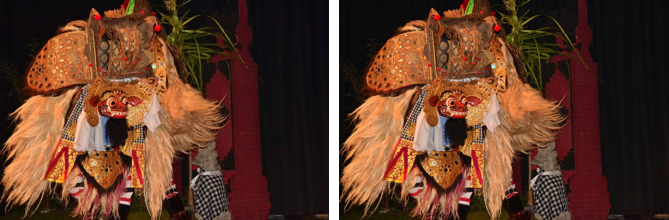

hamming=0 | train:images/svl_143496656.jpg  vs  train:images/svl_147563016.jpg


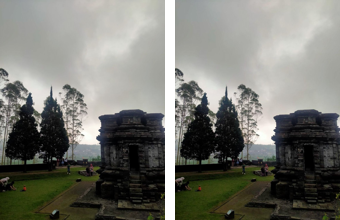

hamming=5 | train:images/svl_147563387.jpg  vs  train:images/svl_147563388.jpg


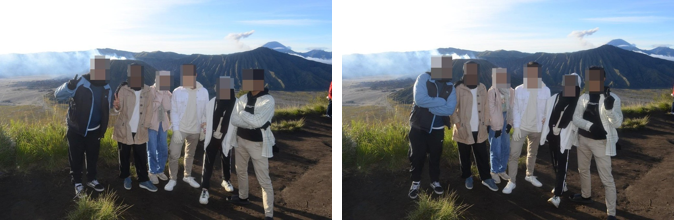

In [7]:
# CEK VISUAL: jangan percaya angka saja. Lihat pasangan ini sebelum menulis laporan.
def side_by_side(a, b, h=220):
    ims = []
    for p in (ok.loc[a, "file"], ok.loc[b, "file"]):
        im = Image.open(p).convert("RGB"); w = int(im.width * h / im.height)
        ims.append(im.resize((w, h)))
    canvas = Image.new("RGB", (sum(i.width for i in ims) + 10, h), "white")
    x = 0
    for im in ims: canvas.paste(im, (x, 0)); x += im.width + 10
    return canvas

# urutkan: lintas split dulu (paling berbahaya), lalu jarak terkecil
tampil = sorted(near, key=lambda t: (sp[t[0]] == sp[t[1]], t[2]))[:8]
for a, b, d in tampil:
    print(f"hamming={d} | {ok.loc[a,'split']}:{ok.loc[a,'file']}  vs  {ok.loc[b,'split']}:{ok.loc[b,'file']}")
    display(side_by_side(a, b))

## 6. Caption: duplikat dan kemiripan train vs val

In [8]:
norm = lambda s: re.sub(r"\W+", " ", str(s).lower()).strip()
for col in ["caption_id", "caption_en"]:
    t = set(tr[col].map(norm)); v = va[col].map(norm)
    R[f"{col}_identik"] = int(v.isin(t).sum())
    R[f"{col}_dup_val"] = int(v.duplicated(keep=False).sum())
    tt = [set(x.split()) for x in t]
    n = 0
    for x in v.unique():
        sx = set(x.split())
        if sx and any(len(sx & s) / len(sx | s) >= 0.8 for s in tt): n += 1
    R[f"{col}_mirip"] = n
    print(f"{col}: val identik dgn train: {R[f'{col}_identik']} | duplikat dalam val: {R[f'{col}_dup_val']} | val mirip (Jaccard>=0.8) dgn train: {n}")

R["id_sama_en"] = int((df.caption_id.map(norm) == df.caption_en.map(norm)).sum())
print("caption_id sama dengan caption_en:", R["id_sama_en"])
for c in ["caption_id", "caption_en"]:
    print(c, "median panjang (kata):", int(df[c].astype(str).str.split().str.len().median()))

caption_id: val identik dgn train: 11 | duplikat dalam val: 2 | val mirip (Jaccard>=0.8) dgn train: 14
caption_en: val identik dgn train: 11 | duplikat dalam val: 2 | val mirip (Jaccard>=0.8) dgn train: 12
caption_id sama dengan caption_en: 11
caption_id median panjang (kata): 11
caption_en median panjang (kata): 12


## 7. Sebaran kategori dan wilayah

split,train,val,All,%val
category,,,,
All,2072,275,2347,11.7
kuliner,792,106,898,11.8
lain-lain,394,52,446,11.7
tarian,243,32,275,11.6
arsitektur/bangunan,179,24,203,11.8
wayang/seni,132,18,150,12.0
tempat/alam,129,17,146,11.6
pakaian/tekstil,93,12,105,11.4
flora/fauna,58,8,66,12.1



Sebaran wilayah (10 teratas):


loc
Indonesia                                                      2280
Indonesia, Malaysia                                              20
Indonesia, Malaysia, Singapore                                   18
Indonesia, Thailand                                               5
Indonesia, Malaysia, Singapore, Thailand                          4
Indonesia, Singapore                                              3
Brunei, Indonesia, Malaysia, Singapore, Thailand                  3
Indonesia, Vietnam                                                2
Cambodia, Indonesia, Malaysia, Singapore, Thailand, Vietnam       2
Brunei, Indonesia, Malaysia, Singapore                            2
Name: count, dtype: int64

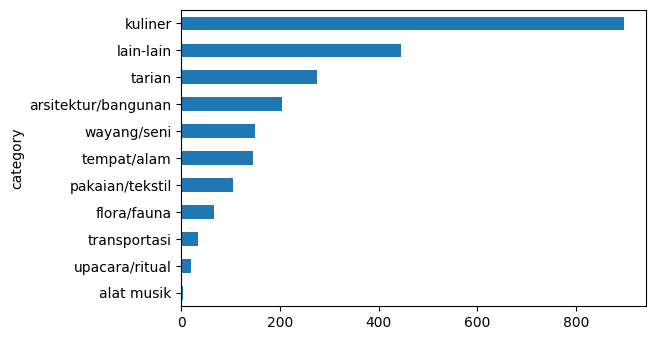

In [9]:
cat = pd.crosstab(df["category"], df["split"], margins=True)
cat["%val"] = (cat["val"] / cat["All"] * 100).round(1)
cat = cat.sort_values("All", ascending=False)
display(cat)
ct = cat.drop(index="All")
R["kat_terbesar"] = (ct.index[0], int(ct["All"].iloc[0]), round(ct["All"].iloc[0] / len(df) * 100, 1))
R["kat_terkecil"] = (ct.index[-1], int(ct["All"].iloc[-1]), round(ct["All"].iloc[-1] / len(df) * 100, 1))
R["n_kat"] = len(ct)
R["kat_val_kecil"] = ct[ct["val"] < 10].index.tolist()   # kelas yang <10 gambar di val
ct["All"].plot.barh(figsize=(6, max(2, len(ct) * 0.35))).invert_yaxis()

if "loc" in df.columns:
    print("\nSebaran wilayah (10 teratas):")
    display(df["loc"].value_counts().head(10))
    R["loc_top"] = df["loc"].value_counts().index[0]

## 8. Ringkasan untuk proposal (bagian 7)

In [10]:
print(R, "\n")
teks = (
f"Pemeriksaan bundel (train {R['n_tr']} baris, val {R['n_va']} baris) menemukan "
f"{R['exact_grup']} grup gambar identik (md5) dan {R['near']} pasangan near-duplicate (dHash, Hamming<={THR}), "
f"dengan {R['exact_lintas']} grup identik dan {R['near_lintas']} pasangan near-duplicate lintas train/val. "
f"Caption val yang identik dengan train berjumlah {R['caption_id_identik']} (ID) dan {R['caption_en_identik']} (EN); "
f"yang mirip (Jaccard>=0.8) {R['caption_id_mirip']} (ID) dan {R['caption_en_mirip']} (EN). "
f"Terdapat {R['n_kat']} kategori; terbesar '{R['kat_terbesar'][0]}' ({R['kat_terbesar'][1]}, {R['kat_terbesar'][2]}%), "
f"terkecil '{R['kat_terkecil'][0]}' ({R['kat_terkecil'][1]}, {R['kat_terkecil'][2]}%). "
f"Hal yang perlu diwaspadai: [ISI MANUAL dari temuan di atas, mis. file berulang di val = {R['file_berulang_val']} baris, "
f"kategori dengan <10 gambar di val = {R['kat_val_kecil']}]. Temuan ini ditindaklanjuti pada audit leakage M2."
)
print(teks)

{'n_tr': 2072, 'n_va': 275, 'file_hilang': 0, 'kosong_caption_id': 0, 'kosong_caption_en': 0, 'kosong_category': 0, 'file_berulang_train': 0, 'file_berulang_val': 0, 'exact_grup': 0, 'exact_lintas': 0, 'near': 3, 'near_lintas': 1, 'caption_id_identik': 11, 'caption_id_dup_val': 2, 'caption_id_mirip': 14, 'caption_en_identik': 11, 'caption_en_dup_val': 2, 'caption_en_mirip': 12, 'id_sama_en': 11, 'kat_terbesar': ('kuliner', 898, np.float64(38.3)), 'kat_terkecil': ('alat musik', 4, np.float64(0.2)), 'n_kat': 11, 'kat_val_kecil': ['flora/fauna', 'transportasi', 'upacara/ritual', 'alat musik'], 'loc_top': 'Indonesia'} 

Pemeriksaan bundel (train 2072 baris, val 275 baris) menemukan 0 grup gambar identik (md5) dan 3 pasangan near-duplicate (dHash, Hamming<=5), dengan 0 grup identik dan 1 pasangan near-duplicate lintas train/val. Caption val yang identik dengan train berjumlah 11 (ID) dan 11 (EN); yang mirip (Jaccard>=0.8) 14 (ID) dan 12 (EN). Terdapat 11 kategori; terbesar 'kuliner' (898, 3